# Lab 4 · Classification metrics and CNN design — Guided notebook

**BME · MSc Deep Learning / VITMMA19 · Fall 2026/2027**
Department of Telecommunications and Artificial Intelligence
**Instructor:** Dr. Mohammed Salah Al-Radhi

**30 minutes, including setup.** Then complete the 60-minute assignment, **02_BME_DL_Lab4_Assignment.ipynb**, independently.

In Labs 2–3 you trained classifiers and compared settings under a fixed budget. Today's lecture added two questions: *how do we judge a classifier beyond accuracy?* and *what do convolution, stride, padding, pooling and dilation actually do?* This notebook works through both with small, fast examples.

By the end, you should be able to compute cross-entropy correctly, predict a layer's output size and parameter count, explain the difference between equivariance and invariance, and derive precision, recall and ROC trade-offs from a confusion matrix.

| Minutes | Activity |
| --- | --- |
| 0–4 | Setup and the shifted-digits data |
| 4–9 | Accuracy, cross-entropy, and logits |
| 9–15 | Convolution arithmetic: output size, parameters, receptive field |
| 15–19 | Equivariance: what happens when the input moves? |
| 19–25 | From a confusion matrix to precision, recall and ROC |
| 25–30 | The experiment engine, a first baseline, and the assignment challenge |

Save a copy in Drive. **A CPU runtime is sufficient; a GPU is optional.** The digits ship with scikit-learn, so no download or external account is needed.

## 1. Setup and the shifted-digits data · minutes 0–4

We reuse the 1,797 scikit-learn digits and the **same stratified split IDs as Lab 3** (1,077 / 360 / 360). Each 8×8 digit is enlarged to 16×16 and pasted onto an empty 32×32 field.

- **Training** digits are always **centred** (top-left corner at row 8, column 8).
- **Validation** has two views of the *same* 360 images: *centred*, and *shifted* to one fixed random position each.
- **Test** data stay closed throughout this guided notebook.

The normalisation mean and standard deviation come from the centred **training** images only, as in Labs 1–2. The helper cells below are identical to those in the assignment.

In [1]:
import copy
import math
import os
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(2, os.cpu_count() or 1))
SEED = 42
SPLIT_SEED = 2026                    # the same stratified split IDs as Lab 3
EPOCHS, BATCH_SIZE, LR = 15, 64, 3e-3
CANVAS, GLYPH, CENTRE = 32, 16, 8    # a 16x16 digit on a 32x32 field; centred offset = 8
MAX_OFFSET = CANVAS - GLYPH          # 16: furthest top-left position
POSITIVE, MIN_RECALL = 8, 0.90       # the "is it an 8?" detector in T4-T5
PHASES = ['debug', 'arch', 'aug', 'claim', 'extension']
CANDIDATE_PHASES = ['arch', 'aug', 'claim']   # runs that may become the final model
RUNS, TEST_OPENED = {}, False
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)

print('Python:', platform.python_version(), '| PyTorch:', torch.__version__,
      '| scikit-learn:', sklearn.__version__)
print('Device:', DEVICE, '| CPU threads:', torch.get_num_threads())
print(f'Epochs {EPOCHS} | batch {BATCH_SIZE} | Adam lr {LR} | seed {SEED}')

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | scikit-learn: 1.9.1
Device: cpu | CPU threads: 2
Epochs 15 | batch 64 | Adam lr 0.003 | seed 42


In [2]:
#@title Provided data helpers — run this cell; expand to inspect
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def to_glyphs(images8):
    """8x8 scikit-learn digits (values 0-16) -> 16x16 float images in [0, 1]."""
    x = torch.tensor(images8 / 16.0, dtype=torch.float32).unsqueeze(1)
    return F.interpolate(x, size=(GLYPH, GLYPH), mode='bilinear', align_corners=False).clamp(0, 1)

def place(glyphs, rows, cols):
    """Paste each 16x16 glyph onto an empty 32x32 field with its top-left corner at (row, col)."""
    n = glyphs.shape[0]
    field = torch.zeros(n, 1, CANVAS, CANVAS)
    offsets = torch.arange(GLYPH)
    r = (rows.long().view(n, 1) + offsets).view(n, GLYPH, 1)
    c = (cols.long().view(n, 1) + offsets).view(n, 1, GLYPH)
    field[torch.arange(n).view(n, 1, 1), 0, r, c] = glyphs[:, 0]
    return field

def centred(glyphs):
    n = len(glyphs)
    return place(glyphs, torch.full((n,), CENTRE), torch.full((n,), CENTRE))

def fixed_random_positions(n, seed):
    g = torch.Generator().manual_seed(seed)
    return (torch.randint(0, MAX_OFFSET + 1, (n,), generator=g),
            torch.randint(0, MAX_OFFSET + 1, (n,), generator=g))

def normalise(x):
    return (x - DATA['mean']) / DATA['std']

def rotate(glyphs, gen, max_deg):
    n = glyphs.shape[0]
    angle = (torch.rand(n, generator=gen) * 2 - 1) * math.radians(max_deg)
    cos, sin, zero = torch.cos(angle), torch.sin(angle), torch.zeros(n)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)
    grid = F.affine_grid(theta, list(glyphs.shape), align_corners=False)
    return F.grid_sample(glyphs, grid, align_corners=False, padding_mode='zeros')

def make_training_batch(glyphs, gen, max_shift=0, rotate_deg=0.0, hflip=False):
    """Training-only augmentation, drawn afresh for every mini-batch. Validation/test are never augmented."""
    n = glyphs.shape[0]
    if rotate_deg > 0:
        glyphs = rotate(glyphs, gen, rotate_deg)
    if hflip:
        flip = torch.rand(n, generator=gen) < 0.5
        glyphs = torch.where(flip.view(n, 1, 1, 1), glyphs.flip(-1), glyphs)
    rows = torch.randint(CENTRE - max_shift, CENTRE + max_shift + 1, (n,), generator=gen)
    cols = torch.randint(CENTRE - max_shift, CENTRE + max_shift + 1, (n,), generator=gen)
    return normalise(place(glyphs, rows, cols))

def prepare_data():
    digits = load_digits()
    ids = np.arange(len(digits.target))
    dev_ids, test_ids = train_test_split(ids, test_size=0.2, stratify=digits.target,
                                         random_state=SPLIT_SEED)
    train_ids, val_ids = train_test_split(dev_ids, test_size=0.25, stratify=digits.target[dev_ids],
                                          random_state=SPLIT_SEED)
    assert set(train_ids).isdisjoint(val_ids) and set(train_ids).isdisjoint(test_ids)
    assert set(val_ids).isdisjoint(test_ids)
    train_g, val_g = to_glyphs(digits.images[train_ids]), to_glyphs(digits.images[val_ids])
    train_canvas = centred(train_g)   # statistics from centred TRAINING images only
    data = dict(train_glyphs=train_g, y_train=torch.tensor(digits.target[train_ids]),
                val_glyphs=val_g, y_val=torch.tensor(digits.target[val_ids]),
                mean=train_canvas.mean().item(), std=train_canvas.std().item(),
                sizes=(len(train_ids), len(val_ids), len(test_ids)))
    rows, cols = fixed_random_positions(len(val_g), seed=202)
    data['val_shift_rows'], data['val_shift_cols'] = rows, cols
    data['val_centred_raw'], data['val_shifted_raw'] = centred(val_g), place(val_g, rows, cols)

    def final_test(run, threshold, positive=POSITIVE):
        """Teaching guard, not security: call once, after the decision is written down."""
        global TEST_OPENED
        if TEST_OPENED:
            raise RuntimeError('The test set was already opened. Reuse final_report; do not retune.')
        if run['phase'] not in CANDIDATE_PHASES or run['status'] != 'complete':
            raise ValueError('Choose a completed T3/T5a candidate run.')
        TEST_OPENED = True
        g, y = to_glyphs(digits.images[test_ids]), torch.tensor(digits.target[test_ids])
        r, c = fixed_random_positions(len(g), seed=303)
        shifted_raw = place(g, r, c)
        probs = predict_proba(run['model'], normalise(shifted_raw))
        return dict(run_name=run['name'], n=len(y), threshold=float(threshold), positive=positive,
                    centred=evaluate(run['model'], normalise(centred(g)), y),
                    shifted=evaluate(run['model'], normalise(shifted_raw), y),
                    y_true=y.numpy(), probs=probs, y_pred=probs.argmax(1),
                    images=shifted_raw[:, 0].numpy())
    return data, final_test

def show_examples():
    fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
    views = [('Training (centred)', centred(DATA['train_glyphs'][:8]), DATA['y_train'][:8]),
             ('Validation (shifted)', DATA['val_shifted_raw'][:8], DATA['y_val'][:8])]
    for row, (title, images, labels) in enumerate(views):
        for i, ax in enumerate(axes[row]):
            ax.imshow(images[i, 0], cmap='gray_r', vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(str(int(labels[i])), fontsize=9)
        axes[row, 0].set_ylabel(title, fontsize=9)
    fig.tight_layout()
    plt.show()

Train / validation / held-out test: (1077, 360, 360)
Input shape: (360, 1, 32, 32) | labels: torch.int64
Training-only pixel mean 0.0763, std 0.2071
Validation digits per class: [36 36 35 37 36 37 36 36 35 36]


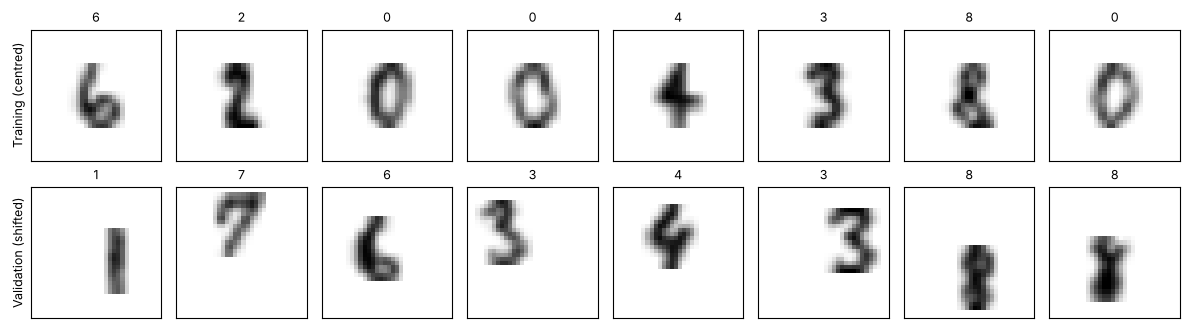

In [3]:
DATA, open_test_once = prepare_data()
VAL = {'centred': (normalise(DATA['val_centred_raw']), DATA['y_val']),
       'shifted': (normalise(DATA['val_shifted_raw']), DATA['y_val'])}
print('Train / validation / held-out test:', DATA['sizes'])
print('Input shape:', tuple(VAL['shifted'][0].shape), '| labels:', DATA['y_val'].dtype)
print(f"Training-only pixel mean {DATA['mean']:.4f}, std {DATA['std']:.4f}")
print('Validation digits per class:', np.bincount(DATA['y_val'].numpy()))
show_examples()

### Supplied experiment engine and plotting helpers (identical to the assignment)

Run both cells now; we use a few helpers in sections 3–6. Section 6 explains how the engine trains a model.

In [4]:
#@title Provided engine: models, evaluation, training, log
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def backbone():
    """Three blocks of [3x3 conv, padding 1] -> ReLU -> 2x2 max pooling. 32x32 -> 32 x 4 x 4."""
    return [nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]

def mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(CANVAS * CANVAS, 128), nn.ReLU(), nn.Linear(128, 10))

@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    logits = model(x.to(DEVICE))
    y = y.to(DEVICE)
    return {'loss': F.cross_entropy(logits, y).item(),
            'acc': (logits.argmax(1) == y).float().mean().item()}

@torch.no_grad()
def predict_proba(model, x):
    model.eval()
    return F.softmax(model(x.to(DEVICE)), dim=1).cpu().numpy()

def run_experiment(name, model_fn, phase, max_shift=0, rotate_deg=0.0, hflip=False,
                   seed=SEED, loss='ce', verbose=True):
    """Fresh model and optimizer; fixed 15-epoch budget; final-epoch model; no test access."""
    if phase not in PHASES:
        raise ValueError(f'phase must be one of {PHASES}')
    if TEST_OPENED and phase != 'extension':
        raise RuntimeError('The test set is open. Only phase="extension" runs are allowed now, '
                           'and they cannot change your T5 decision.')
    if not (0 <= int(max_shift) <= CENTRE and 0 <= float(rotate_deg) <= 180 and loss in ('ce', 'mse')):
        raise ValueError('Use 0 <= max_shift <= 8, 0 <= rotate_deg <= 180, loss "ce" or "mse".')
    aug = dict(max_shift=int(max_shift), rotate_deg=float(rotate_deg), hflip=bool(hflip))
    set_seed(seed)
    model = model_fn().to(DEVICE)
    signature = (str(model), tuple(aug.items()), seed, phase, loss, EPOCHS, LR, BATCH_SIZE)
    if name in RUNS:
        if RUNS[name]['signature'] != signature:
            raise ValueError(f'"{name}" already records a different experiment. Choose a new name; '
                             'the earlier run stays in the log.')
        if verbose:
            print(f'{name}: settings unchanged, reusing the recorded run.')
        return RUNS[name]
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    shuffle_gen = torch.Generator().manual_seed(seed + 1000)
    aug_gen = torch.Generator().manual_seed(seed + 2000)
    x_all, y_all = DATA['train_glyphs'], DATA['y_train']
    history, status, start = [], 'complete', time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(y_all), generator=shuffle_gen)
        total, correct = 0.0, 0
        for s in range(0, len(order), BATCH_SIZE):
            idx = order[s:s + BATCH_SIZE]
            x = make_training_batch(x_all[idx], aug_gen, **aug).to(DEVICE)
            y = y_all[idx].to(DEVICE)
            logits = model(x)
            if loss == 'ce':
                batch_loss = F.cross_entropy(logits, y)
            else:  # regression-style loss on probabilities, used only in deeper investigation D3
                batch_loss = F.mse_loss(F.softmax(logits, 1), F.one_hot(y, 10).float())
            optimizer.zero_grad()
            batch_loss.backward()
            optimizer.step()
            total += batch_loss.item() * len(idx)
            correct += (logits.argmax(1) == y).sum().item()
        if not math.isfinite(total):
            status = 'failed'
            break
        c, sh = evaluate(model, *VAL['centred']), evaluate(model, *VAL['shifted'])
        history.append(dict(epoch=epoch, train_loss=total / len(y_all), train_acc=correct / len(y_all),
                            val_c_loss=c['loss'], val_c_acc=c['acc'],
                            val_s_loss=sh['loss'], val_s_acc=sh['acc']))
    history = pd.DataFrame(history)
    last = history.iloc[-1] if len(history) else {}
    run = dict(name=name, phase=phase, model_name=model_fn.__name__, model=model.eval(), seed=seed,
               loss=loss, status=status, signature=signature, history=history,
               parameters=count_parameters(model), seconds=time.perf_counter() - start, **aug,
               **{k: float(last[k]) for k in ['train_loss', 'val_c_loss', 'val_c_acc',
                                              'val_s_loss', 'val_s_acc'] if len(history)})
    RUNS[name] = run
    if verbose:
        print(f"{name:22s} {status} | params {run['parameters']:7,d} | {run['seconds']:5.1f} s | "
              f"train loss {run.get('train_loss', float('nan')):.3f} | "
              f"centred val CE {run.get('val_c_loss', float('nan')):.3f} acc {run.get('val_c_acc', float('nan')):.3f} | "
              f"shifted val CE {run.get('val_s_loss', float('nan')):.3f} acc {run.get('val_s_acc', float('nan')):.3f}")
    return run

def experiment_table(phases=None):
    cols = ['name', 'phase', 'model_name', 'max_shift', 'rotate_deg', 'hflip', 'loss', 'seed', 'status',
            'parameters', 'train_loss', 'val_c_loss', 'val_c_acc', 'val_s_loss', 'val_s_acc', 'seconds']
    table = pd.DataFrame([{k: r.get(k) for k in cols} for r in RUNS.values()], columns=cols)
    return table if phases is None else table[table.phase.isin(phases)].reset_index(drop=True)

In [5]:
#@title Provided analysis and plotting helpers
def plot_curves(runs, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for run in runs:
        h = run['history']
        axes[0].plot(h.epoch, h.train_loss, label=run['name'])
        axes[1].plot(h.epoch, h.val_c_acc, label=run['name'])
        axes[2].plot(h.epoch, h.val_s_acc, label=run['name'])
    axes[0].set(xlabel='Epoch', ylabel='Training loss', title='Training loss')
    axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Centred validation', ylim=(0, 1.02))
    axes[2].set(xlabel='Epoch', ylabel='Accuracy', title='Shifted validation', ylim=(0, 1.02))
    for ax in axes:
        ax.grid(alpha=.25)
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

@torch.no_grad()
def shift_profile(model):
    """Validation accuracy when every digit sits at the vertical centre and column offset 0..16."""
    g, y, n = DATA['val_glyphs'], DATA['y_val'], len(DATA['y_val'])
    return np.array([evaluate(model, normalise(place(g, torch.full((n,), CENTRE), torch.full((n,), col))), y)['acc']
                     for col in range(MAX_OFFSET + 1)])

def plot_shift_profile(runs, title='Accuracy versus horizontal position'):
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for run in runs:
        ax.plot(range(MAX_OFFSET + 1), shift_profile(run['model']), 'o-', ms=3, label=run['name'])
    ax.axvline(CENTRE, color='grey', ls=':', lw=1)
    ax.set(xlabel='Column of the digit\'s left edge (8 = centred, as in training)',
           ylabel='Validation accuracy', ylim=(0, 1.02), xticks=range(0, MAX_OFFSET + 1, 2), title=title)
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

def show_confusion(model, view='shifted', title=None):
    x, y = VAL[view]
    pred = predict_proba(model, x).argmax(1)
    cm = confusion_matrix(y.numpy(), pred, labels=np.arange(10))
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(ax=ax, colorbar=False)
    ax.set(title=title or f'{view} validation | rows = true, columns = predicted')
    fig.tight_layout()
    plt.show()
    return cm

def show_errors(model, label, view='shifted', n=8):
    """Validation errors involving `label` in either direction: true label missed, or wrongly predicted."""
    x, y = VAL[view]
    pred, y = predict_proba(model, x).argmax(1), y.numpy()
    raw = DATA['val_shifted_raw'] if view == 'shifted' else DATA['val_centred_raw']
    idx = np.flatnonzero(((y == label) | (pred == label)) & (pred != y))[:n]
    if len(idx) == 0:
        print(f'No errors involving {label} in the {view} view.')
        return
    fig, axes = plt.subplots(1, len(idx), figsize=(1.6 * len(idx), 2.1), squeeze=False)
    for ax, i in zip(axes.flat, idx):
        ax.imshow(raw[i, 0], cmap='gray_r', vmin=0, vmax=1)
        ax.set_title(f'true {y[i]} / pred {pred[i]}', fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'Errors involving {label} ({view} validation)', fontsize=10)
    fig.tight_layout()
    plt.show()

def top_confusions(cm, n=4):
    off = [(int(cm[i, j]), i, j) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0]
    return ', '.join(f'true {i} -> pred {j}: {c}' for c, i, j in sorted(off, reverse=True)[:n]) or 'none'

def measure_receptive_field(layers, size=64, seed=0):
    """Empirical receptive field: input pixels whose gradient reaches the central output unit."""
    torch.manual_seed(seed)
    net = nn.Sequential(*layers).eval()
    x = torch.randn(16, 1, size, size, requires_grad=True)
    out = net(x)
    out[:, :, out.shape[-2] // 2, out.shape[-1] // 2].sum().backward()
    nz = torch.nonzero(x.grad.abs().sum((0, 1)))
    return int(nz[:, 0].max() - nz[:, 0].min() + 1)

@torch.no_grad()
def equivariance_check(shifts=(3, 4, 8, 16)):
    """Untrained backbone, 64x64 empty field: shift the digits right by s pixels and ask whether the
    final feature map is simply the original map moved by k whole cells (interior cells only)."""
    torch.manual_seed(0)
    net = nn.Sequential(*backbone()).eval()
    g = DATA['val_glyphs'][:64]
    def field(col):
        x = torch.zeros(len(g), 1, 64, 64)
        x[:, :, 24:40, col:col + GLYPH] = g
        return x
    base = net(field(24))
    rows = []
    for s in shifts:
        moved = net(field(24 + s))
        errors = [((moved[..., 1:-1, 1 + k:-1] - base[..., 1:-1, 1:base.shape[-1] - 1 - k]).norm()
                   / base[..., 1:-1, 1:base.shape[-1] - 1 - k].norm()).item() for k in range(3)]
        k = int(np.argmin(errors))
        rows.append(dict(shift_px=s, best_cell_shift=k, relative_error=round(errors[k], 4)))
    return pd.DataFrame(rows)

def check_layer_predictions(predictions, layers):
    rows = []
    for key, (layer, in_shape) in layers.items():
        out = tuple(layer(torch.zeros(1, *in_shape)).shape[1:])
        actual = out + (count_parameters(layer),)
        pred = predictions.get(key)
        rows.append(dict(layer=key, spec=str(layer), input=in_shape, predicted=pred, actual=actual,
                         match='yes' if pred is not None and tuple(pred) == actual else 'NO'))
    return pd.DataFrame(rows)

**Check:** the shifted view contains the same digits, only moved. If a model is good on the centred view but poor on the shifted one, what has it learned besides the shape of each digit?

## 2. Accuracy, cross-entropy, and logits · minutes 4–9

For one sample, cross-entropy is $-\log p(\text{true class})$; we average over samples. **Predict:** what is the cross-entropy of a model that always outputs the uniform distribution over 3 classes? *Answer: $\ln 3 \approx 1.099$.*

Below, two models classify four images as cat, dog or bird. **Predict before running:** do they have the same accuracy? Which one would you trust more?

In [6]:
P_a = torch.tensor([[0.40, 0.35, 0.25], [0.30, 0.45, 0.25], [0.20, 0.30, 0.50], [0.50, 0.30, 0.20]])
P_b = torch.tensor([[0.90, 0.05, 0.05], [0.05, 0.90, 0.05], [0.05, 0.05, 0.90], [0.80, 0.10, 0.10]])
y = torch.tensor([0, 1, 2, 1])   # cat, dog, bird, dog
for name, P in [('Model A', P_a), ('Model B', P_b)]:
    acc = (P.argmax(1) == y).float().mean().item()
    ce = -torch.log(P[torch.arange(len(y)), y]).mean().item()   # straight from the definition
    print(f'{name}: accuracy {acc:.2f} | cross-entropy {ce:.4f}')
print('Uniform prediction over 3 classes:', round(math.log(3), 4))

Model A: accuracy 0.75 | cross-entropy 0.9030
Model B: accuracy 0.75 | cross-entropy 0.6547
Uniform prediction over 3 classes: 1.0986


Both models are 75% accurate, but B gives the true class far more probability on the images it gets right. It is also more confidently wrong on the fourth image. Cross-entropy sees both effects; accuracy sees neither.

**PyTorch losses take logits, not probabilities.** `F.cross_entropy(logits, y)` applies `log_softmax` internally (stable log-sum-exp) and then the negative log-likelihood. With probabilities you have two correct options: `F.nll_loss(torch.log(P), y)`, or the definition above. Watch what happens if probabilities are passed in as if they were logits:

In [7]:
logits = torch.log(P_b)                         # any logits whose softmax is P_b
print('F.cross_entropy(logits, y)      :', round(F.cross_entropy(logits, y).item(), 4))
print('F.nll_loss(log P, y)            :', round(F.nll_loss(torch.log(P_b), y).item(), 4))
print('F.cross_entropy(P, y)  <- a bug :', round(F.cross_entropy(P_b, y).item(), 4))
print('softmax(P) row 0:', [round(v, 3) for v in F.softmax(P_b, 1)[0].tolist()], '<- much flatter than [0.9, 0.05, 0.05]')

F.cross_entropy(logits, y)      : 0.6547
F.nll_loss(log P, y)            : 0.6547
F.cross_entropy(P, y)  <- a bug : 0.8108
softmax(P) row 0: [0.539, 0.23, 0.23] <- much flatter than [0.9, 0.05, 0.05]


A second softmax squeezes values in [0, 1] towards a uniform distribution (here 0.9 becomes 0.54), so the loss looks plausible but is wrong. In **T1** you will meet the same mistake hidden inside a network.

## 3. Convolution arithmetic · minutes 9–15

PyTorch's "convolution" is a cross-correlation: the kernel slides over the input without being flipped, exactly as on the lecture slide. **Predict** the first output value of the slide example before running: $0\cdot2 + 1\cdot1 + 2\cdot1 + 3\cdot3 = 12$.

In [8]:
x = torch.tensor([[0, 1, 2, 1, 3, 1, 4],
                  [2, 3, 1, 0, 0, 1, 2],
                  [3, 4, 2, 1, 1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 7)
kernel = torch.tensor([[2., 1.], [1., 3.]]).view(1, 1, 2, 2)
print(F.conv2d(x, kernel))   # the lecture's example: 12 10 6 5 10 13 / 22 17 7 4 2 7

tensor([[[[12., 10.,  6.,  5., 10., 13.],
          [22., 17.,  7.,  4.,  2.,  7.]]]])


For kernel $k$, stride $s$, padding $p$ and dilation $d$:

$$H_\text{out} = \left\lfloor \frac{H + 2p - d(k-1) - 1}{s} \right\rfloor + 1, \qquad \text{conv parameters} = C_\text{out}\,(C_\text{in}\,k^2 + 1).$$

Dilation spreads the kernel out, so its *effective* size is $d(k-1)+1$. **Predict** each output size and parameter count, then compare with PyTorch:

In [9]:
def conv_out(H, k, s=1, p=0, d=1):
    return (H + 2 * p - d * (k - 1) - 1) // s + 1

examples = [
    ('Conv2d(3, 16, k=3)',                 nn.Conv2d(3, 16, 3),                      (3, 28, 28), dict(k=3)),
    ('Conv2d(3, 16, k=5, padding=2)',      nn.Conv2d(3, 16, 5, padding=2),           (3, 28, 28), dict(k=5, p=2)),
    ('Conv2d(3, 16, k=3, stride=2)',       nn.Conv2d(3, 16, 3, stride=2),            (3, 28, 28), dict(k=3, s=2)),
    ('Conv2d(3, 16, k=3, dilation=3)',     nn.Conv2d(3, 16, 3, dilation=3),          (3, 28, 28), dict(k=3, d=3)),
    ('MaxPool2d(3, stride=2)',             nn.MaxPool2d(3, stride=2),                (16, 28, 28), dict(k=3, s=2)),
]
rows = []
for name, layer, shape, kw in examples:
    out = layer(torch.zeros(1, *shape)).shape
    rows.append(dict(layer=name, input=shape, formula_H=conv_out(shape[1], **kw), pytorch_output=tuple(out[1:]),
                     parameters=count_parameters(layer)))
display(pd.DataFrame(rows))

,layer,input,formula_H,pytorch_output,parameters
0,"Conv2d(3, 16, k=3)","(3, 28, 28)",26,"(16, 26, 26)",448
1,"Conv2d(3, 16, k=5, padding=2)","(3, 28, 28)",28,"(16, 28, 28)",1216
2,"Conv2d(3, 16, k=3, stride=2)","(3, 28, 28)",13,"(16, 13, 13)",448
3,"Conv2d(3, 16, k=3, dilation=3)","(3, 28, 28)",22,"(16, 22, 22)",448
4,"MaxPool2d(3, stride=2)","(16, 28, 28)",13,"(16, 13, 13)",0


The three 3×3 convolutions all have **448 parameters** = 16 × (3 × 9 + 1), whatever their stride or dilation; the 5×5 one has 16 × (3 × 25 + 1) = 1,216. Stride, padding and dilation change *where* the kernel is applied and therefore the output size, not how many weights it has. Pooling has no parameters at all.

**Receptive field:** the input region that can influence one output unit. Each layer adds $(k_\text{eff}-1)\times j$ pixels, where $j$ is the product of all earlier strides. The helper `measure_receptive_field` finds it empirically, from the input pixels whose gradient reaches the central output unit.

In [10]:
for name, layers in [('one 5x5 conv', [nn.Conv2d(1, 4, 5, padding=2)]),
                     ('3x3 conv -> 2x2 max-pool', [nn.Conv2d(1, 4, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]),
                     ('3x3 conv, dilation 3', [nn.Conv2d(1, 4, 3, padding=3, dilation=3)])]:
    print(f'{name:28s} receptive field = {measure_receptive_field(layers)} px')

one 5x5 conv                 receptive field = 5 px
3x3 conv -> 2x2 max-pool     receptive field = 4 px
3x3 conv, dilation 3         receptive field = 7 px


5 = 1 + 4; 4 = 1 + 2 (conv) + 1 × 1 (pool, since $j = 1$ before it); 7 = 1 + 2 × 3. In **T2** you will predict the receptive fields of deeper stacks, including the CNN used in the assignment.

## 4. Equivariance: what happens when the input moves? · minutes 15–19

The same kernel is applied at every position (*shared weights*). So if the input moves, the feature map should move with it: this is **equivariance**. A classifier needs **invariance**: the same answer wherever the digit is. These are not the same thing.

We place one digit on an empty 64×64 field and move it right by $s$ pixels. **Predict:** for a stride-1 convolution, which shifts reproduce the original feature map, just moved? For a stride-2 convolution?

In [11]:
digit = DATA['val_glyphs'][:1]
def field(col):
    x = torch.zeros(1, 1, 64, 64)
    x[:, :, 24:40, col:col + GLYPH] = digit
    return x

def moved_copy_error(layer, shift, stride):
    """Is layer(shifted input) the original output moved by shift/stride cells? (interior only)"""
    with torch.no_grad():
        base, moved = layer(field(24)), layer(field(24 + shift))
    cells = shift // stride
    a, b = moved[..., 2:-2, 2 + cells:-2], base[..., 2:-2, 2:base.shape[-1] - 2 - cells]
    return ((a - b).norm() / b.norm()).item()

torch.manual_seed(0)
conv_s1 = nn.Conv2d(1, 4, 3, padding=1)
conv_s2 = nn.Conv2d(1, 4, 3, stride=2, padding=1)
for shift in [1, 2, 3, 4]:
    print(f'shift {shift} px | stride 1: error {moved_copy_error(conv_s1, shift, 1):.4f} | '
          f'stride 2: error {moved_copy_error(conv_s2, shift, 2):.4f}')

shift 1 px | stride 1: error 0.0000 | stride 2: error 0.1522
shift 2 px | stride 1: error 0.0000 | stride 2: error 0.0000
shift 3 px | stride 1: error 0.0000 | stride 2: error 0.1550
shift 4 px | stride 1: error 0.0000 | stride 2: error 0.0000


A stride-1 convolution is equivariant to every shift (error 0). A stride-2 convolution only reproduces the map for **even** shifts; an odd shift falls between output cells and changes the feature *values*. Random, untrained weights are enough here: equivariance comes from the architecture, not from training.

**Carry this into the assignment (T2c, T3):** the assignment's CNN has three 2×2 pooling stages. Which shifts will it handle exactly? And equivariance alone does not make the *classifier* invariant: that depends on how the final feature map becomes 10 logits.

## 5. From a confusion matrix to precision, recall and ROC · minutes 19–25

The lecture's 3-class example (84 test images). **Rows are the true class and columns the prediction**, as in scikit-learn; some books swap them, so always read the axis labels.

For a chosen positive class, everything else is "negative": TP is the diagonal cell, FP the rest of that **column**, FN the rest of that **row**, and TN everything else. **Predict** the four counts for *car* before running.

In [12]:
CLASSES = ['rocket', 'car', 'airplane']
LECTURE_CM = np.array([[15, 3, 8], [4, 23, 1], [9, 2, 19]])
k = CLASSES.index('car')
TP = int(LECTURE_CM[k, k])
FP = int(LECTURE_CM[:, k].sum()) - TP
FN = int(LECTURE_CM[k, :].sum()) - TP
TN = int(LECTURE_CM.sum()) - TP - FP - FN
print(f'car: TP {TP}, FP {FP}, FN {FN}, TN {TN}  (sum {TP + FP + FN + TN})')
print(f'precision {TP / (TP + FP):.3f} | recall {TP / (TP + FN):.3f} | '
      f'specificity {TN / (TN + FP):.3f} | FPR {FP / (FP + TN):.3f}')
print('overall accuracy', round(np.trace(LECTURE_CM) / LECTURE_CM.sum(), 3))

# Cross-check with scikit-learn by expanding the matrix back into label lists.
y_true = np.repeat(np.repeat(np.arange(3), 3), LECTURE_CM.ravel())
y_pred = np.repeat(np.tile(np.arange(3), 3), LECTURE_CM.ravel())
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[k])
print('scikit-learn: precision', round(p[0], 3), '| recall', round(r[0], 3), '| F1', round(f1[0], 3))

car: TP 23, FP 5, FN 5, TN 51  (sum 84)
precision 0.821 | recall 0.821 | specificity 0.911 | FPR 0.089
overall accuracy 0.679
scikit-learn: precision 0.821 | recall 0.821 | F1 0.821


A classifier usually outputs a **score**, and a threshold turns it into a decision. Moving the threshold trades recall (TPR) against false alarms (FPR); the **ROC curve** shows every trade-off, and its area (AUC) summarises how well positives are ranked above negatives. **Predict:** with 10% positives, what accuracy does a rule that always says "negative" get?

AUC 0.856 | "always negative" accuracy 0.90


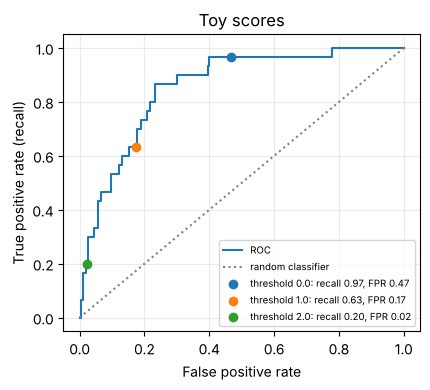

In [13]:
rng = np.random.default_rng(0)
y_bin = np.r_[np.ones(30, dtype=bool), np.zeros(270, dtype=bool)]       # 10% positives
score = np.r_[rng.normal(1.5, 1, 30), rng.normal(0, 1, 270)]          # positives score higher on average
fpr, tpr, _ = roc_curve(y_bin, score)
print(f'AUC {roc_auc_score(y_bin, score):.3f} | "always negative" accuracy {1 - y_bin.mean():.2f}')
fig, ax = plt.subplots(figsize=(4.4, 4))
ax.plot(fpr, tpr, label='ROC')
ax.plot([0, 1], [0, 1], ':', color='grey', label='random classifier')
for t in [0.0, 1.0, 2.0]:
    pred = score >= t
    rec, fp_rate = pred[y_bin].mean(), pred[~y_bin].mean()
    ax.scatter([fp_rate], [rec], zorder=3, label=f'threshold {t}: recall {rec:.2f}, FPR {fp_rate:.2f}')
ax.set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='Toy scores')
ax.legend(fontsize=7); ax.grid(alpha=.25); fig.tight_layout(); plt.show()

"Always negative" is 90% accurate and detects nothing. This is why accuracy alone misleads when a class is rare, and why recall, precision, F1 and ROC are reported for the class that matters. A threshold is a fitted choice: pick it on **validation** data, never on test. In **T4** you will choose one under a recall requirement.

## 6. The experiment engine and a first baseline · minutes 25–30

The assignment uses a supplied engine (identical cells below). `run_experiment` builds a fresh model with seed 42, trains it for exactly **15 epochs** with Adam (learning rate 3e-3), keeps the **final-epoch** model, and logs centred and shifted validation results every epoch. Optional augmentation is drawn afresh for every training batch; validation and test are never augmented. Expand the engine cell in section 1 and find where the seed is set, where `make_training_batch` is called, and where the validation views are evaluated.

**Training-time augmentation preview.** Slide 57: augmentation is only for training data, and it must not change the label. Here `max_shift` places the digit at a random position within ±`max_shift` pixels of the centre. No model is trained in this cell.

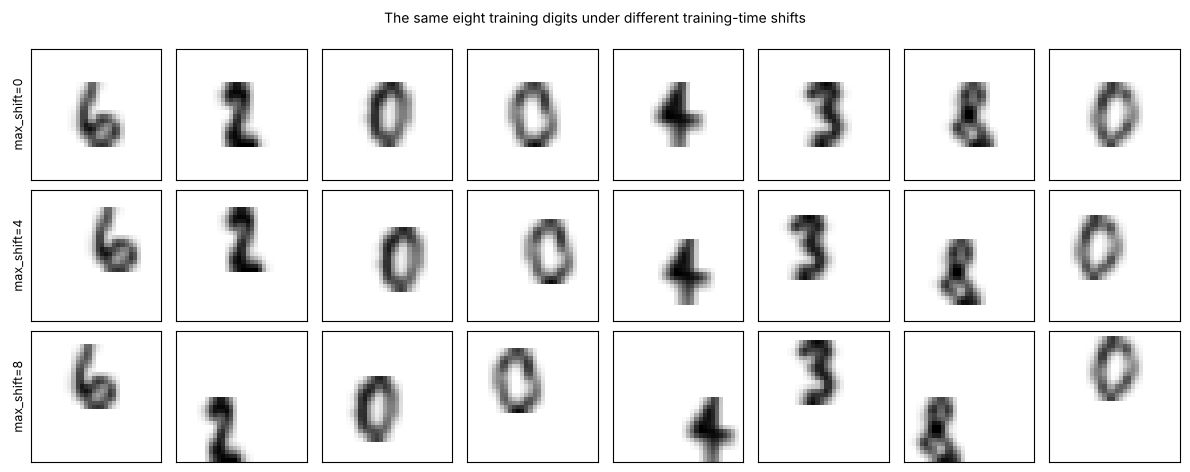

In [14]:
gen = torch.Generator().manual_seed(0)
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for row, s in enumerate([0, 4, 8]):
    batch = make_training_batch(DATA['train_glyphs'][:8], gen, max_shift=s) * DATA['std'] + DATA['mean']
    for i, ax in enumerate(axes[row]):
        ax.imshow(batch[i, 0], cmap='gray_r', vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(f'max_shift={s}', fontsize=9)
fig.suptitle('The same eight training digits under different training-time shifts', fontsize=10)
fig.tight_layout(); plt.show()

**A first baseline.** The Lab 2–3 style MLP flattens all 1,024 pixels. **Predict before running:** its centred validation accuracy, and its accuracy when the digit is moved left or right.

Guided_MLP             complete | params 132,490 |   0.9 s | train loss 0.064 | centred val CE 0.095 acc 0.964 | shifted val CE 6.601 acc 0.144


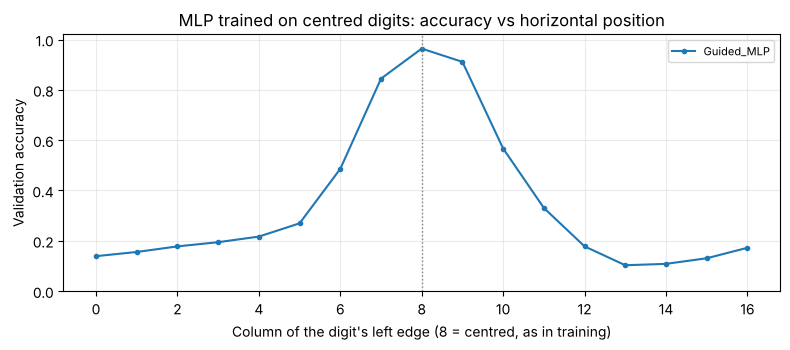

In [15]:
guided_mlp = run_experiment('Guided_MLP', mlp, 'arch')
plot_shift_profile([guided_mlp], 'MLP trained on centred digits: accuracy vs horizontal position')

The MLP is about 96% accurate where it was trained and collapses within a few pixels of the centre: each of its weights belongs to one pixel position.

## The assignment challenge

The form scanner's digits can appear anywhere. In the assignment you will:

1. **T1** debug a classification loss inside a teammate's CNN;
2. **T2** predict shapes, parameters and receptive fields, and test which shifts the assignment's CNN handles exactly;
3. **T3** find out whether convolution, global pooling or augmentation makes the classifier robust to position, predicting first;
4. **T4** evaluate an "is it an 8?" detector beyond accuracy;
5. **T5** test a claim (an AI suggestion, or a supplied one), freeze your decision, and open the test set once.

We stop here without evaluating any test data. Start the assignment now.

## Optional after class · Hand-crafted filters produce feature maps

The lecture showed sharpen and edge-detection kernels applied to a photo. A CNN *learns* such kernels instead of having them designed. The cell below applies the lecture's three kernels to one digit. This section is **not part of the 30-minute guided session or grading**.

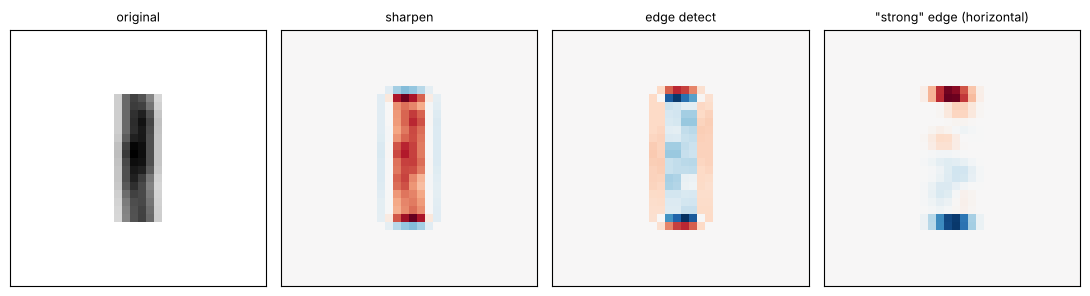

Interactive tools from the lecture: poloclub.github.io/cnn-explainer, github.com/vdumoulin/conv_arithmetic


In [16]:
RUN_OPTIONAL_FILTERS = True
if RUN_OPTIONAL_FILTERS:
    kernels = {'sharpen': [[0, -1, 0], [-1, 5, -1], [0, -1, 0]],
               'edge detect': [[0, 1, 0], [1, -4, 1], [0, 1, 0]],
               '"strong" edge (horizontal)': [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]}
    img = DATA['val_centred_raw'][:1]
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))
    axes[0].imshow(img[0, 0], cmap='gray_r'); axes[0].set_title('original', fontsize=9)
    for ax, (name, kern) in zip(axes[1:], kernels.items()):
        out = F.conv2d(img, torch.tensor(kern, dtype=torch.float32).view(1, 1, 3, 3), padding=1)
        v = out.abs().max().item()
        ax.imshow(out[0, 0], cmap='RdBu_r', vmin=-v, vmax=v); ax.set_title(name, fontsize=9)
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); plt.show()
    print('Interactive tools from the lecture: poloclub.github.io/cnn-explainer, '
          'github.com/vdumoulin/conv_arithmetic')

## References and credits

- BME lecture: *Deep Learning — Classification & Convolutional Neural Networks* (20 October 2026), supplied course slides.
- [scikit-learn: the 8×8 digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), derived from the UCI Optical Recognition of Handwritten Digits data (E. Alpaydin, C. Kaynak). This is **not MNIST**. The 32×32 placement is an artificial classroom transformation, not a new benchmark.
- [scikit-learn: metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html) and [Google ML Crash Course: ROC and AUC](https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc).
- [PyTorch: `torch.nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and [`CrossEntropyLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).
- Dumoulin & Visin (2016), [A guide to convolution arithmetic for deep learning](https://arxiv.org/abs/1603.07285); interactive [CNN Explainer](https://poloclub.github.io/cnn-explainer/).

Course material: Dr. Mohammed Salah Al-Radhi, BME. Dataset and framework credits remain with their authors.